In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import os
import seaborn as sns

In [2]:
import sys
from analysis import *

sys.path.append('../')
import pipeline_utility as pu

In [3]:
from analysis import small_label_settings, large_label_settings
plt.style.use('default')
plt.rcParams.update(small_label_settings)

In [4]:
# Load data
file = os.path.join('..', 'experiments', 'full_pipeline', 'final_data.csv') 
df = pd.read_csv(file)

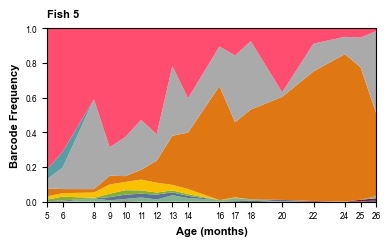

In [5]:
fish_id = 'fish5'

fig, ax = plt.subplots(figsize=(4.25, 2.25))
pu.plot_muller(df, fish_id, ax, map_samples=True)

ax.set_xlabel('Age (months)', fontsize=8, fontweight='bold', fontfamily='Arial')
ax.set_ylabel('Barcode Frequency', fontsize=8, fontweight='bold', fontfamily='Arial')
ax.set_title(f'Fish {fish_id[4:]}', fontsize=8, fontweight='bold', fontfamily='Arial', pad=8, loc = 'left')

plt.savefig(os.path.join('images', 'muller', f'muller_{fish_id}.svg'), bbox_inches='tight', transparent=True)
plt.savefig(os.path.join('images', 'muller', f'muller_{fish_id}.png'), dpi=300, bbox_inches='tight')

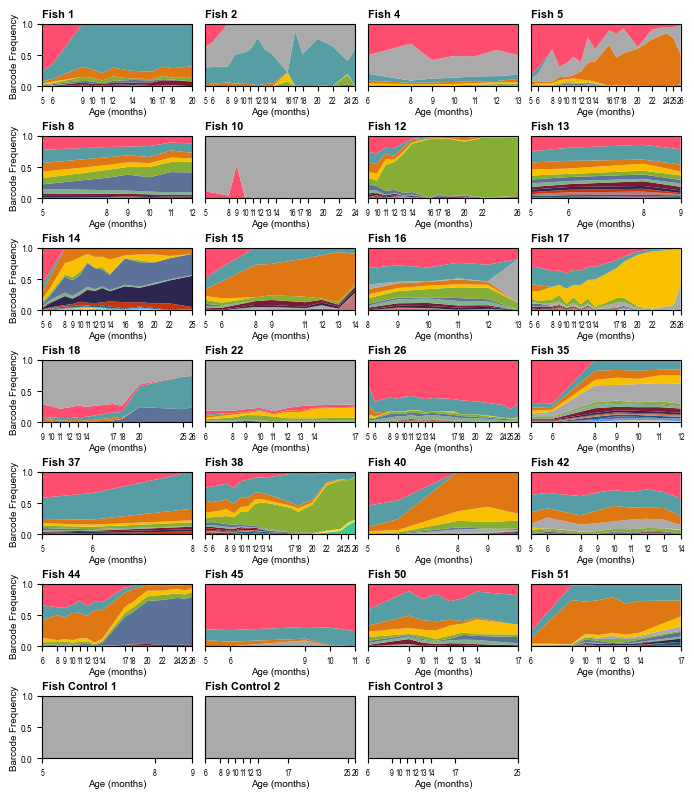

In [6]:
# List of fish to plot
fish_list = ['fish1', 'fish2', 'fish4', 'fish5', 'fish8', 'fish10',
            'fish12', 'fish13', 'fish14', 'fish15', 'fish16', 'fish17',
            'fish18', 'fish22', 'fish26', 'fish35', 'fish37', 'fish38',
            'fish40', 'fish42', 'fish44', 'fish45', 'fish50', 
             'fish51', 'fishctrl1', 'fishctrl2', 'fishctrl3'
            ]

# Define your custom color palette
custom_colors = ["#ff4d6f", "#579ea4", "#df7713", "#f9c000", "#86ad34",
              "#5d7298", "#81b28d", "#7e1a2f", "#2d2651", "#c8350d", "#bd777a",
              '#1a5f7a', '#C86BCE', '#75B6FF', '#F9FD7F', '#006400', '#FFC4DE',
              '#FA8072', '#D8FC74', '#571B64', '#00b4d8', '#CA2A6F']

# Sample map - maps sample numbers to fish age in months
sample_map = {
    1: 5, 2: 6, 3: 7, 4: 8, 5: 9, 6: 10, 7: 11, 8: 12, 9: 13, 10: 14,
    11: 16, 12: 17, 13: 18, 14: 20, 15: 22, 16: 24, 17: 25, 18: 26
}

# Determine grid layout
n_fish = len(fish_list)
n_cols = 4  # Number of columns in the grid
n_rows = -(-n_fish // n_cols)  # Ceiling division

# Create figure with subplots
fig, axes = plt.subplots(n_rows, n_cols, figsize=(7, 8))

# Flatten axes array for easier iteration
if n_fish == 1:
    axes = np.array([axes])
else:
    axes = axes.flatten()

# Mark unedited barcode
unedited_barcode = 'NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE'

# Plot each fish
for idx, fish_id in enumerate(fish_list):
    ax = axes[idx]

    pu.plot_muller(df, fish_id, ax, map_samples=True)
    
    title = fish_id.replace('fish', 'Fish ').replace('ctrl', 'Control ')
    ax.set_title(title, fontsize=8, fontweight='bold', fontfamily='Arial', pad=5, loc = 'left')
    
    ax.set_xlabel('Age (months)', fontsize=7, fontfamily='Arial')
    if idx % n_cols == 0:
        ax.set_ylabel('Barcode Frequency', fontsize=7, fontfamily='Arial')
    else:
        ax.set_ylabel('')
        ax.set_yticks([])
    ax.xaxis.labelpad = 1.5
    ax.yaxis.labelpad = 1.5
    
    ax.set_ylim(0, 1)
    for label in ax.get_xticklabels():
        label.set_fontname('Arial Narrow')

# Hide any unused subplots
for idx in range(n_fish, len(axes)):
    axes[idx].set_visible(False)

# Adjust layout
plt.tight_layout(h_pad=0.5, w_pad=0.75)

# Save the plot
plt.savefig(os.path.join('images', 'muller', 'muller_faceted_all_fish.svg'), bbox_inches='tight', transparent=True)
plt.savefig(os.path.join('images', 'muller', 'muller_faceted_all_fish.png'), dpi=300, bbox_inches='tight')

# Display
plt.show()